# Ablation study: missing-RSSI encoding and WAP feature pruning

**Part A.** Compare ways of encoding "WAP not detected" (zer-varaince vs full 520).
**Part B.** compare WAP pruning strategies.

In [1]:
import os
import time
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import BaseEstimator, ClassifierMixin
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix

SEED = 42
TRAIN_PATH = os.environ.get("TRAIN_PATH", "C:\\Users\\Madis\\Downloads\\preprocessing\\train_cleaned.csv")
VAL_PATH = os.environ.get("VAL_PATH", "C:\\Users\\Madis\\Downloads\\preprocessing\\validation_cleaned.csv")
N_TREES = int(os.environ.get("N_TREES", 300))
from pathlib import Path
OUT_DIR = Path(os.environ.get("OUT_DIR", "ablation_outputs"))
OUT_DIR.mkdir(parents=True, exist_ok=True)

## Load data and split 

In [2]:
train_df = pd.read_csv(TRAIN_PATH)
val_df = pd.read_csv(VAL_PATH)
# Extract 520 WAP columns and target label
wap_cols = [c for c in train_df.columns if c.startswith("WAP")]
X_train_raw = train_df[wap_cols]
y_train_raw = train_df["LOCATION_CLASS"]

X_holdout_raw = val_df[wap_cols]
y_holdout = val_df["LOCATION_CLASS"]

# Stratified 80/20 train/test split (matching team seed)
X_train, X_test, y_train, y_test = train_test_split(
    X_train_raw, y_train_raw,
    test_size=0.20,
    random_state=42,
    stratify=y_train_raw
)

# Standardize features using StandardScaler (fit on training only)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)
X_holdout_scaled = scaler.transform(X_holdout_raw)

print(f"Training split: {X_train_scaled.shape}")
print(f"Validation split (20%): {X_test_scaled.shape}")
print(f"Held-out test set: {X_holdout_scaled.shape}")


# build mapping from LOCATION_CLASS to integer label and building-floor pair
location_classes = np.sort(train_df["LOCATION_CLASS"].unique()) 
CLASS_TO_ID = {class_label: index for index, class_label in enumerate(location_classes)} 
LABELS = np.arange(len(location_classes))
class_floor = train_df[["LOCATION_CLASS", "BUILDINGID", "FLOOR"]].drop_duplicates()
if class_floor["LOCATION_CLASS"].duplicated().any():
    raise ValueError("A LOCATION_CLASS maps to more than one building-floor pair")
CLASS_TO_FLOOR = dict(zip(
    class_floor["LOCATION_CLASS"],
    zip(class_floor["BUILDINGID"].astype(int), class_floor["FLOOR"].astype(int)),
))
FLOOR_PAIRS = sorted(set(CLASS_TO_FLOOR.values()))
if len(FLOOR_PAIRS) != 13:
    raise ValueError(f"Expected 13 building-floor pairs, found {len(FLOOR_PAIRS)}")
FLOOR_LABELS = [f"B{building}-F{floor}" for building, floor in FLOOR_PAIRS]
CLASS_TO_FLOOR_ID = {
    CLASS_TO_ID[class_label]: FLOOR_PAIRS.index(pair)
    for class_label, pair in CLASS_TO_FLOOR.items()
}


Training split: (15440, 520)
Validation split (20%): (3860, 520)
Held-out test set: (1111, 520)


In [3]:
# NumPy copies of the unscaled splits
X_tr = X_train.to_numpy(dtype=float)
X_te = X_test.to_numpy(dtype=float)
X_ho = X_holdout_raw.to_numpy(dtype=float)

# Labels: map string LOCATION_CLASS -> integer ids
y_tr = y_train.map(CLASS_TO_ID).to_numpy()
y_te = y_test.map(CLASS_TO_ID).to_numpy()
y_ho = y_holdout.map(CLASS_TO_ID).to_numpy()

# Fail loudly if any label wasn't in the training class list (map gives NaN)
for name, y in [("y_tr", y_tr), ("y_te", y_te), ("y_ho", y_ho)]:
    if pd.isna(y).any():
        raise ValueError(f"{name} contains LOCATION_CLASS values not seen in train_df")
y_tr, y_te, y_ho = (y.astype(int) for y in (y_tr, y_te, y_ho))

# missing-value detection
vals = X_tr[~np.isnan(X_tr)]
MISSING = -110.0 if (vals == -110).any() else float(
    np.unique(vals, return_counts=True)[0][np.argmax(np.unique(vals, return_counts=True)[1])])

def missing_mask(X):
    return np.isnan(X) | (X == MISSING)

print(f"Missing values in training split: {missing_mask(X_tr).mean():.2%}")
print(f"Missing values in validation split: {missing_mask(X_te).mean():.2%}")
print(f"Missing values in holdout split: {missing_mask(X_ho).mean():.2%}")

Missing values in training split: 96.57%
Missing values in validation split: 96.54%
Missing values in holdout split: 96.83%


In [4]:
MISSING_RSSI = -110.0


def missing_mask(X):
    return np.isnan(X) | (X == MISSING_RSSI)


if not missing_mask(X_tr).any():
    raise ValueError(f"No -110 dBm sentinel found in the training split")


def encode_missing(X, fill_value):
    if fill_value not in (-110.0, 0.0):
        raise ValueError(f"Unsupported missing-RSSI fill value: {fill_value}")
    return np.where(missing_mask(X), fill_value, X)


# Determine zero-variance features using training rows only, before evaluating either variant.
ZERO_VAR_KEEP = np.var(encode_missing(X_tr, MISSING_RSSI), axis=0) > 0.0
if not ZERO_VAR_KEEP.any():
    raise ValueError("All WAP features have zero variance in the training split")

A_GROUP = "sentinel_imputation"
B_GROUP = "feature_pruning"
A_VARIANTS = {
    "missing_-110dBm": -110.0,
    "impute_0dBm": 0.0,
}
B_VARIANTS = {
    "full_520": np.arange(len(wap_cols)),
    "drop_zero_variance": np.flatnonzero(ZERO_VAR_KEEP),
}

print(f"Missing sentinel: {MISSING_RSSI:g} dBm")
print(f"Feature-pruning comparison: {len(wap_cols)} full WAPs vs. {ZERO_VAR_KEEP.sum()} non-zero-variance WAPs")


Missing sentinel: -110 dBm
Feature-pruning comparison: 520 full WAPs vs. 461 non-zero-variance WAPs


In [5]:
class ZeroRuleClassifier(BaseEstimator, ClassifierMixin):
    def fit(self, X, y):
        self.classes_, counts = np.unique(y, return_counts=True)
        self.majority_class_ = self.classes_[np.argmax(counts)]
        return self
    def predict(self, X):
        return np.array([self.majority_class_] * len(X))
    def score(self, X, y):
        preds = self.predict(X)
        return np.mean(preds == y)

In [6]:
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset
from sklearn.preprocessing import LabelEncoder

# Set deterministic seed for PyTorch
torch.manual_seed(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")
class IndoorLocalizationMLP(nn.Module):
    def __init__(self, input_dim, num_classes, hidden_dims=(512, 256, 128), dropout_rate=0.2):
        super().__init__()
        layers = []
        previous_dim = input_dim
        for hidden_dim in hidden_dims:
                layers.extend([
                    nn.Linear(previous_dim, hidden_dim),
                    nn.BatchNorm1d(hidden_dim),
                    nn.ReLU(),
                    nn.Dropout(dropout_rate),
                ])
                previous_dim = hidden_dim

        layers.append(nn.Linear(previous_dim, num_classes))
        self.network = nn.Sequential(*layers)
    def forward(self, x):
        return self.network(x)





Using device: cpu


In [7]:
from copy import deepcopy

class MLPTrainer:
    def __init__(self, device, epochs=40, batch_size=128, patience=7):
        self.device = device
        self.epochs = epochs
        self.batch_size = batch_size
        self.patience = patience

    def train(self, model, X_train, X_validation, y_train, y_validation):
        # Fit the encoder on training labels only.
        label_encoder = LabelEncoder()
        y_train_idx = label_encoder.fit_transform(y_train)
        y_validation_idx = label_encoder.transform(y_validation)

        X_train_tensor = torch.as_tensor(X_train, dtype=torch.float32)
        y_train_tensor = torch.as_tensor(y_train_idx, dtype=torch.long)
        X_validation_tensor = torch.as_tensor(X_validation, dtype=torch.float32)
        y_validation_tensor = torch.as_tensor(y_validation_idx, dtype=torch.long)

        train_data = TensorDataset(X_train_tensor, y_train_tensor)
        validation_data = TensorDataset(X_validation_tensor, y_validation_tensor)

        train_loader = DataLoader(
            train_data, batch_size=self.batch_size, shuffle=True
        )
        validation_loader = DataLoader(
            validation_data, batch_size=256, shuffle=False
        )

        counts = np.bincount(y_train_idx, minlength=len(label_encoder.classes_))
        if (counts == 0).any():
            raise ValueError("A training class has no samples.")

        weights = counts.sum() / (len(counts) * counts)
        class_weights = torch.as_tensor(
            weights, dtype=torch.float32, device=self.device
        )
        criterion = nn.CrossEntropyLoss(weight=class_weights)
        optimizer = torch.optim.AdamW(
            model.parameters(), lr=1e-3, weight_decay=1e-4
        )
        scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
            optimizer, mode="min", factor=0.5, patience=3
        )

        best_val_loss = float("inf")
        best_state = None
        patience_counter = 0

        model.to(self.device)

        for epoch in range(1, self.epochs + 1):
            model.train()
            train_loss_sum = 0.0

            for X_batch, y_batch in train_loader:
                X_batch = X_batch.to(self.device)
                y_batch = y_batch.to(self.device)

                optimizer.zero_grad()
                loss = criterion(model(X_batch), y_batch)
                loss.backward()
                optimizer.step()
                train_loss_sum += loss.item() * X_batch.size(0)

            model.eval()
            val_loss_sum = 0.0
            with torch.no_grad():
                for X_batch, y_batch in validation_loader:
                    X_batch = X_batch.to(self.device)
                    y_batch = y_batch.to(self.device)
                    loss = criterion(model(X_batch), y_batch)
                    val_loss_sum += loss.item() * X_batch.size(0)

            val_loss = val_loss_sum / len(validation_data)
            scheduler.step(val_loss)

            if epoch % 5 == 0 or epoch == 1:
                train_loss = train_loss_sum / len(train_data)
                print(
                    f"Epoch {epoch:02d}/{self.epochs} | "
                    f"Train Loss: {train_loss:.4f} | Val Loss: {val_loss:.4f}"
                )

            if val_loss < best_val_loss:
                best_val_loss = val_loss
                best_state = deepcopy(model.state_dict())
                patience_counter = 0
            else:
                patience_counter += 1
                if patience_counter >= self.patience:
                    print(f"Early stopping at epoch {epoch}.")
                    break

        if best_state is None:
            raise RuntimeError("Training did not produce a best model checkpoint.")

        model.load_state_dict(best_state)
        model.eval()
        return model

In [8]:
def make_model(name, experiment=None):
    if name == "k-NN":#best parameters: {'metric': 'manhattan', 'n_neighbors': 1, 'weights': 'uniform'}
        return KNeighborsClassifier(n_neighbors=1, metric="manhattan", weights="uniform")
    
    if name == "Random Forest":#best parameters: {'max_depth': None, 'max_features': 'log2', 'min_samples_split': 2, 'n_estimators': 300}
        return RandomForestClassifier(
            n_estimators=N_TREES,
            max_depth=None,
            max_features="log2",
            min_samples_split=2,
            random_state=42,
        )
    
    if name == "MLP":
        if experiment == "drop_zero_variance":
            input_dim = 461
        else:
            input_dim = 520
        
        return IndoorLocalizationMLP(input_dim=input_dim, num_classes=len(location_classes)).to(device)
    if name == "Zero-Rule Baseline":
        return ZeroRuleClassifier()

    raise ValueError(f"Unknown model: {name}")
MODELS = ["k-NN", "Random Forest", "MLP", "Zero-Rule Baseline"]
rows, preds = [], {}

Note: Knn and random forest and zero rule classifier are tuned and MLP is not tuned.

# Experiment Runner

In [9]:
def run_experiment(group, experiment, model_name, X_train, X_validation, X_holdout):
    key = (group, experiment, model_name)
    started = time.time()
    sc = StandardScaler().fit(X_train)                       # train only, per variant
    Xtr, Xva, Xho = (sc.transform(a) for a in (X_train, X_validation, X_holdout))

    if model_name == "MLP":
        torch.manual_seed(SEED)
        model = make_model(model_name, experiment=experiment)
        trainer = MLPTrainer(device=device, epochs=40, batch_size=128, patience=7)
        model = trainer.train(model, Xtr, Xva, y_tr, y_te)
        fit_seconds = time.time() - started
        with torch.no_grad():
            val_pred = model(torch.as_tensor(Xva, dtype=torch.float32).to(device)).argmax(1).cpu().numpy()
            holdout_pred = model(torch.as_tensor(Xho, dtype=torch.float32).to(device)).argmax(1).cpu().numpy()
    else:
        model = make_model(model_name)
        model.fit(Xtr, y_tr)
        fit_seconds = time.time() - started
        val_pred = model.predict(Xva)
        holdout_pred = model.predict(Xho)

    rows[:] = [r for r in rows if (r["group"], r["experiment"], r["model"]) != key]
    rows.append({
        "group": group, "experiment": experiment, "model": model_name,
        "n_features": X_train.shape[1],
        "val_acc": accuracy_score(y_te, val_pred) * 100,
        "val_macro_f1": f1_score(y_te, val_pred, average="macro", zero_division=0),
        "holdout_acc": accuracy_score(y_ho, holdout_pred) * 100,
        "holdout_macro_f1": f1_score(y_ho, holdout_pred, average="macro", zero_division=0),
        "fit_seconds": fit_seconds,
    })
    preds[key] = (val_pred, holdout_pred)
    r = rows[-1]
    print(f"[{group}] {experiment:<22} {model_name:<14} features={r['n_features']:<3} "
          f"val macro-F1={r['val_macro_f1']:.4f} | holdout macro-F1={r['holdout_macro_f1']:.4f}")

# Part A: missing-RSSI encoding (all WAPs kept)
missing_-110dBm vs 0dBm

In [10]:
for experiment, fill_value in A_VARIANTS.items():
    X_train_encoded = encode_missing(X_tr, fill_value)
    X_validation_encoded = encode_missing(X_te, fill_value)
    X_holdout_encoded = encode_missing(X_ho, fill_value)
    for model_name in MODELS:
        run_experiment(
            A_GROUP,
            experiment,
            model_name,
            X_train_encoded,
            X_validation_encoded,
            X_holdout_encoded
        )

df_a = pd.DataFrame([r for r in rows if r["group"] == A_GROUP])
df_a.sort_values(["experiment", "model"]).reset_index(drop=True)


[sentinel_imputation] missing_-110dBm        k-NN           features=520 val macro-F1=0.9947 | holdout macro-F1=0.8209
[sentinel_imputation] missing_-110dBm        Random Forest  features=520 val macro-F1=0.9948 | holdout macro-F1=0.8969
Epoch 01/40 | Train Loss: 0.4812 | Val Loss: 0.0608
Epoch 05/40 | Train Loss: 0.0338 | Val Loss: 0.0217
Epoch 10/40 | Train Loss: 0.0169 | Val Loss: 0.0190
Epoch 15/40 | Train Loss: 0.0090 | Val Loss: 0.0132
Epoch 20/40 | Train Loss: 0.0067 | Val Loss: 0.0136
Early stopping at epoch 22.
[sentinel_imputation] missing_-110dBm        MLP            features=520 val macro-F1=0.9965 | holdout macro-F1=0.8705
[sentinel_imputation] missing_-110dBm        Zero-Rule Baseline features=520 val macro-F1=0.0189 | holdout macro-F1=0.0053
[sentinel_imputation] impute_0dBm            k-NN           features=520 val macro-F1=0.9864 | holdout macro-F1=0.7255
[sentinel_imputation] impute_0dBm            Random Forest  features=520 val macro-F1=0.9929 | holdout macro-F1=0

,group,experiment,model,n_features,val_acc,val_macro_f1,holdout_acc,holdout_macro_f1,fit_seconds
0,sentinel_imputation,impute_0dBm,MLP,520,97.823834,0.977744,57.065707,0.559895,791.977260
1,sentinel_imputation,impute_0dBm,Random Forest,520,99.378238,0.992912,88.028803,0.857727,28.833819
2,sentinel_imputation,impute_0dBm,Zero-Rule Baseline,520,14.041451,0.018942,3.600360,0.005347,0.445216
3,sentinel_imputation,impute_0dBm,k-NN,520,98.730570,0.986440,76.057606,0.725498,0.608780
4,sentinel_imputation,missing_-110dBm,MLP,520,99.689119,0.996536,87.578758,0.870549,715.452672
5,sentinel_imputation,missing_-110dBm,Random Forest,520,99.559585,0.994811,91.089109,0.896860,17.226025
6,sentinel_imputation,missing_-110dBm,Zero-Rule Baseline,520,14.041451,0.018942,3.600360,0.005347,0.369164
7,sentinel_imputation,missing_-110dBm,k-NN,520,99.507772,0.994673,84.338434,0.820915,0.734576


## Part B: zero-variance WAP pruning (imputation fixed at -110 dBm)

Compare all 520 WAPs with the WAPs whose training-split variance is non-zero. Variance is computed from training rows only; the sentinel encoding is held fixed to isolate feature pruning.


In [11]:
X_train_base = encode_missing(X_tr, MISSING_RSSI)
X_validation_base = encode_missing(X_te, MISSING_RSSI)
X_holdout_base = encode_missing(X_ho, MISSING_RSSI)

for experiment, columns in B_VARIANTS.items():
    for model_name in MODELS:
        run_experiment(
            B_GROUP,
            experiment,
            model_name,
            X_train_base[:, columns],
            X_validation_base[:, columns],
            X_holdout_base[:, columns],
        )

df_b = pd.DataFrame([r for r in rows if r["group"] == B_GROUP])
df_b.sort_values(["experiment", "model"]).reset_index(drop=True)

[feature_pruning] full_520               k-NN           features=520 val macro-F1=0.9947 | holdout macro-F1=0.8209
[feature_pruning] full_520               Random Forest  features=520 val macro-F1=0.9948 | holdout macro-F1=0.8969
Epoch 01/40 | Train Loss: 0.4812 | Val Loss: 0.0608
Epoch 05/40 | Train Loss: 0.0338 | Val Loss: 0.0217
Epoch 10/40 | Train Loss: 0.0169 | Val Loss: 0.0190
Epoch 15/40 | Train Loss: 0.0090 | Val Loss: 0.0132
Epoch 20/40 | Train Loss: 0.0067 | Val Loss: 0.0136
Early stopping at epoch 22.
[feature_pruning] full_520               MLP            features=520 val macro-F1=0.9965 | holdout macro-F1=0.8705
[feature_pruning] full_520               Zero-Rule Baseline features=520 val macro-F1=0.0189 | holdout macro-F1=0.0053
[feature_pruning] drop_zero_variance     k-NN           features=461 val macro-F1=0.9947 | holdout macro-F1=0.8209
[feature_pruning] drop_zero_variance     Random Forest  features=461 val macro-F1=0.9951 | holdout macro-F1=0.8949
Epoch 01/40 | Trai

,group,experiment,model,n_features,val_acc,val_macro_f1,holdout_acc,holdout_macro_f1,fit_seconds
0,feature_pruning,drop_zero_variance,MLP,461,99.533679,0.995116,90.279028,0.890327,734.668015
1,feature_pruning,drop_zero_variance,Random Forest,461,99.585492,0.995108,90.909091,0.894850,30.832778
2,feature_pruning,drop_zero_variance,Zero-Rule Baseline,461,14.041451,0.018942,3.600360,0.005347,0.409120
3,feature_pruning,drop_zero_variance,k-NN,461,99.507772,0.994673,84.338434,0.820915,0.406106
4,feature_pruning,full_520,MLP,520,99.689119,0.996536,87.578758,0.870549,739.735631
5,feature_pruning,full_520,Random Forest,520,99.559585,0.994811,91.089109,0.896860,17.126154
6,feature_pruning,full_520,Zero-Rule Baseline,520,14.041451,0.018942,3.600360,0.005347,0.466776
7,feature_pruning,full_520,k-NN,520,99.507772,0.994673,84.338434,0.820915,0.627300


# Ablation Results

In [12]:
results = pd.DataFrame(rows)
results = results.sort_values(["group", "experiment", "model"]).reset_index(drop=True)
results.to_csv(OUT_DIR / "ablation_results.csv", index=False)

summary = results[[
    "group", "experiment", "model", "n_features",
    "val_acc", "val_macro_f1", "holdout_acc", "holdout_macro_f1", "fit_seconds",
]].copy()
summary.round({
    "val_acc": 2,
    "val_macro_f1": 4,
    "holdout_acc": 2,
    "holdout_macro_f1": 4,
    "fit_seconds": 1,
})


,group,experiment,model,n_features,val_acc,val_macro_f1,holdout_acc,holdout_macro_f1,fit_seconds
0,feature_pruning,drop_zero_variance,MLP,461,99.53,0.9951,90.28,0.8903,734.7
1,feature_pruning,drop_zero_variance,Random Forest,461,99.59,0.9951,90.91,0.8949,30.8
2,feature_pruning,drop_zero_variance,Zero-Rule Baseline,461,14.04,0.0189,3.60,0.0053,0.4
3,feature_pruning,drop_zero_variance,k-NN,461,99.51,0.9947,84.34,0.8209,0.4
4,feature_pruning,full_520,MLP,520,99.69,0.9965,87.58,0.8705,739.7
5,feature_pruning,full_520,Random Forest,520,99.56,0.9948,91.09,0.8969,17.1
6,feature_pruning,full_520,Zero-Rule Baseline,520,14.04,0.0189,3.60,0.0053,0.5
7,feature_pruning,full_520,k-NN,520,99.51,0.9947,84.34,0.8209,0.6
8,sentinel_imputation,impute_0dBm,MLP,520,97.82,0.9777,57.07,0.5599,792.0
9,sentinel_imputation,impute_0dBm,Random Forest,520,99.38,0.9929,88.03,0.8577,28.8


## 13 x 13 building-floor confusion matrices

Location-class predictions are converted to their building-floor pair. Each matrix has true floor pairs on rows and predicted floor pairs on columns; row-normalized CSVs and plots show the share of samples assigned to each floor, making cross-floor errors visible.


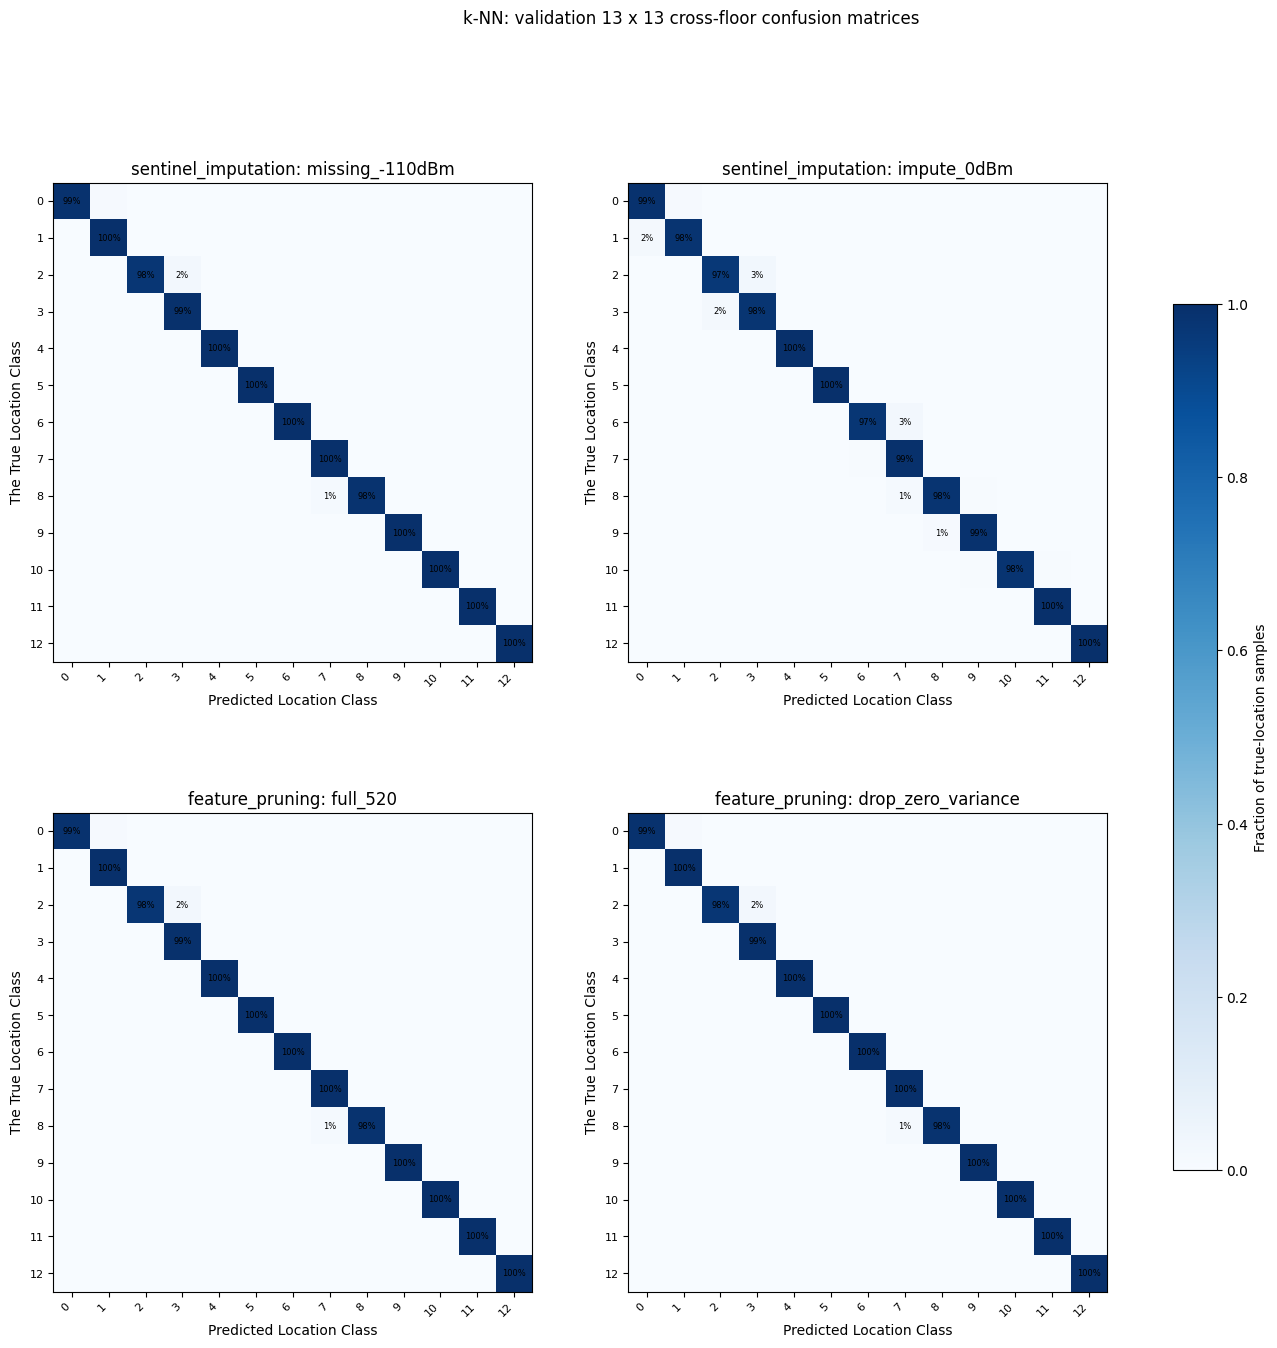

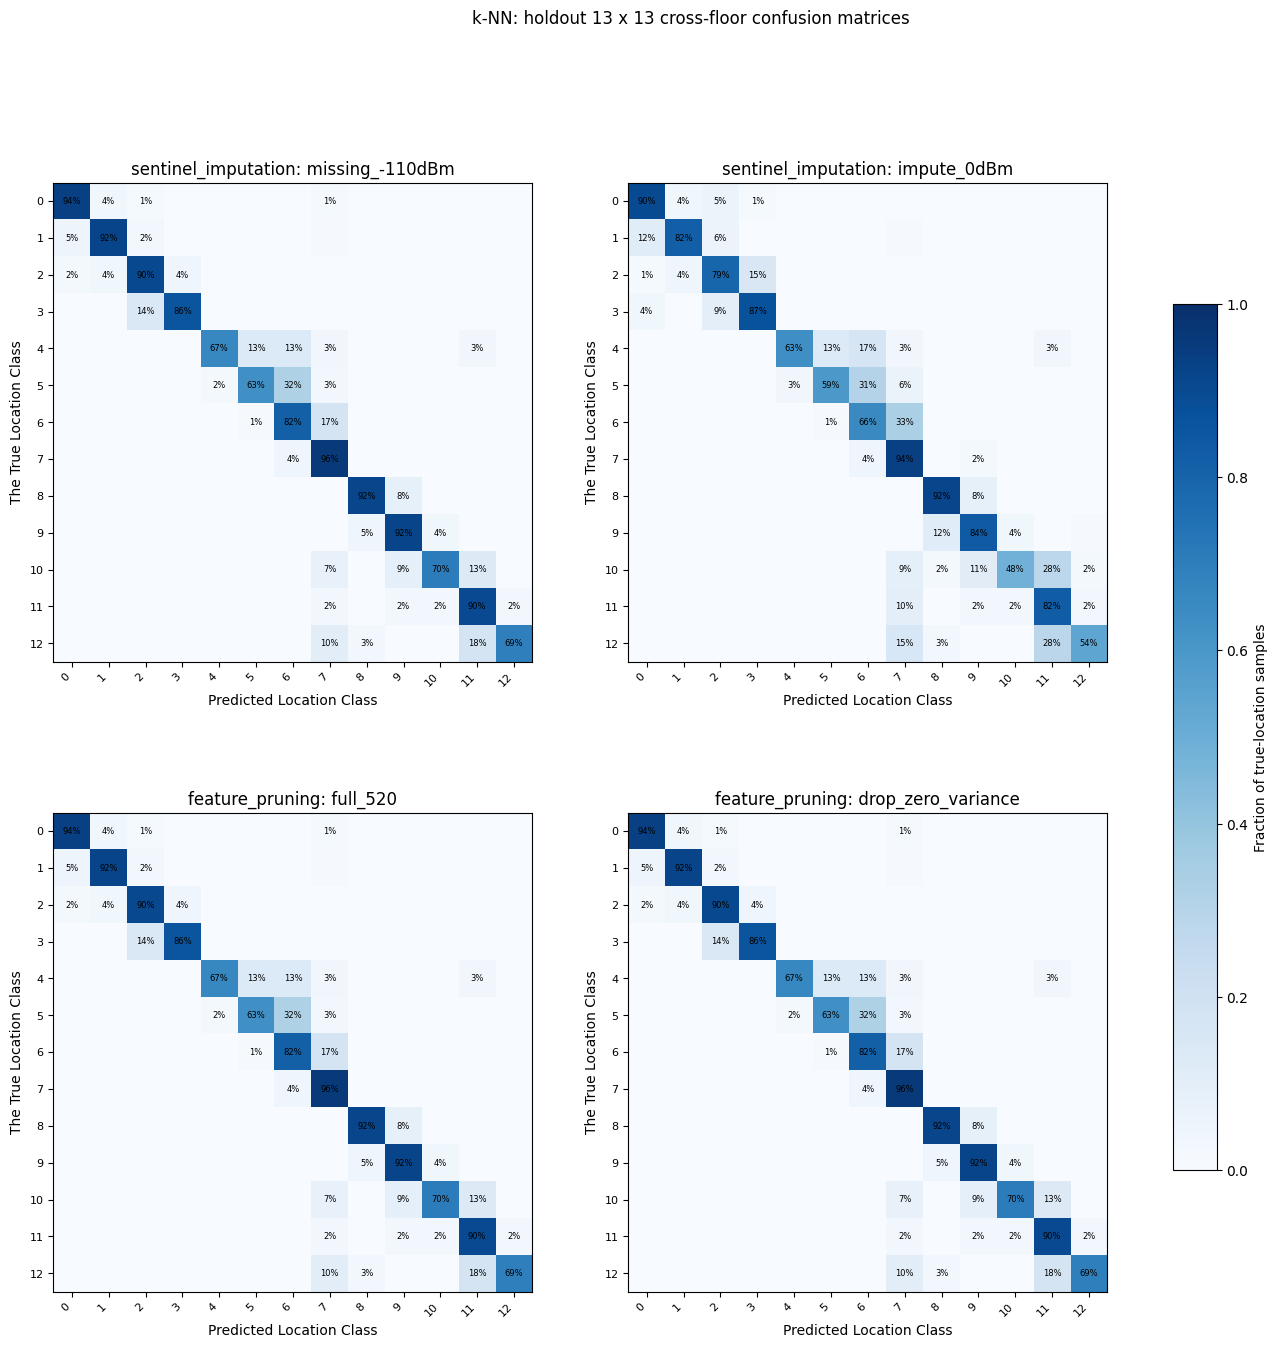

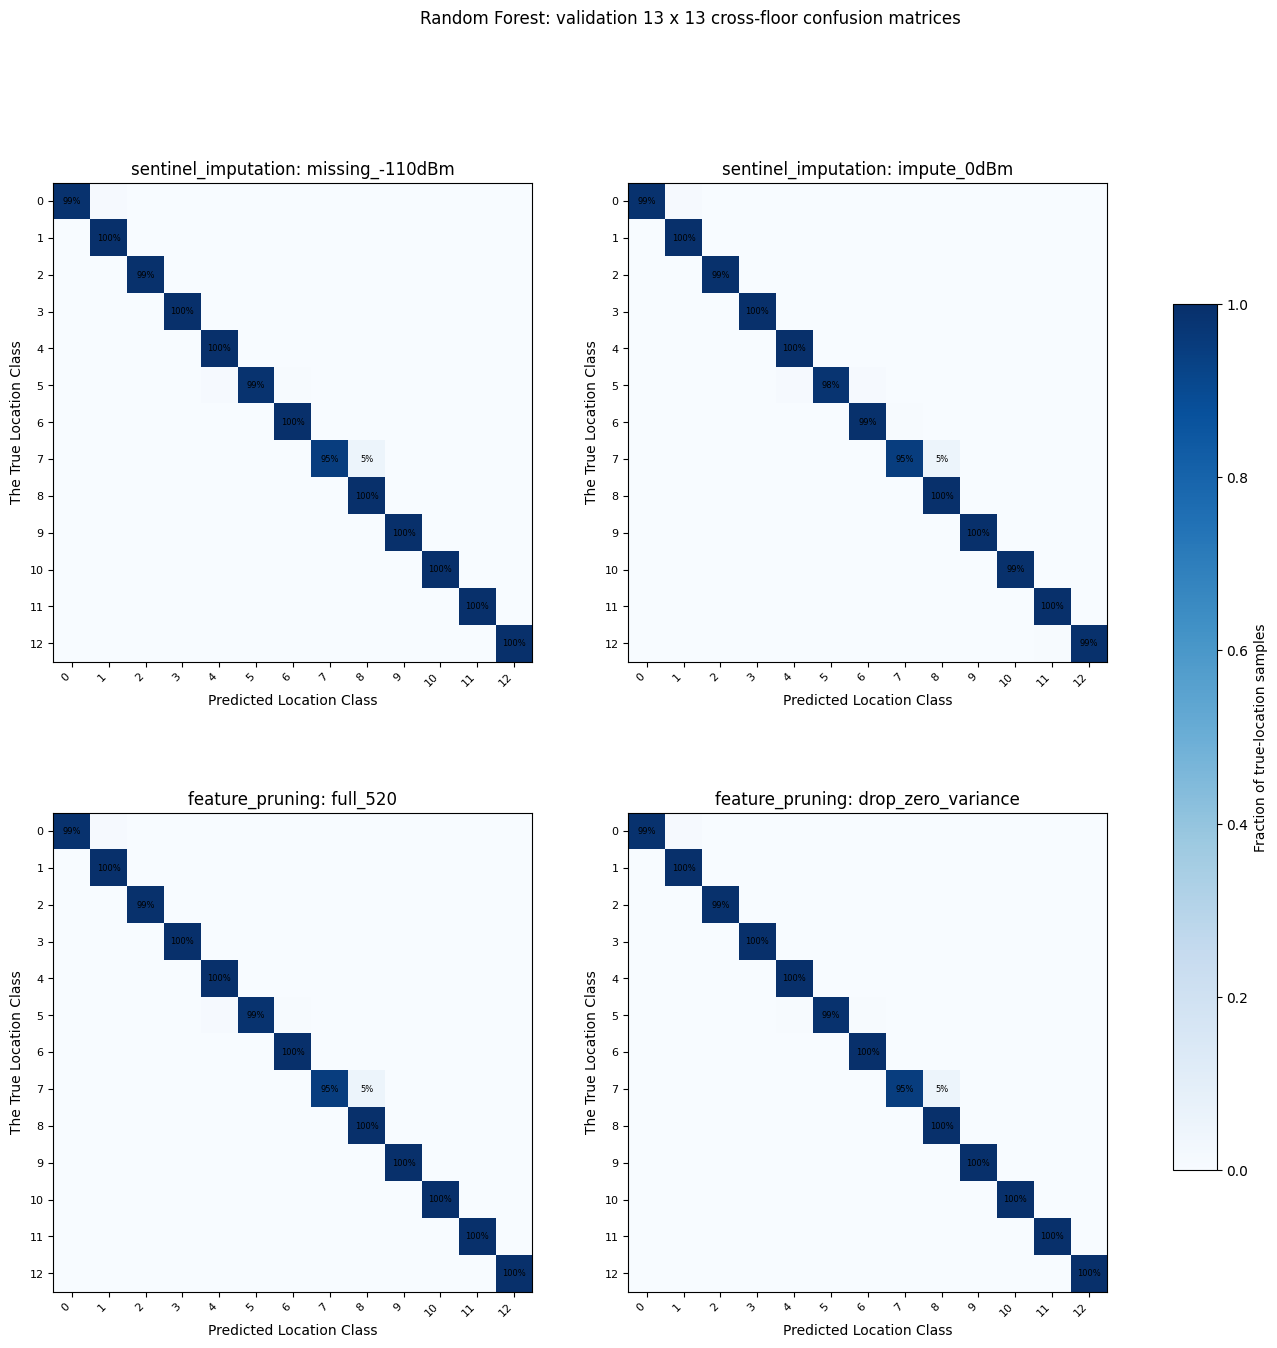

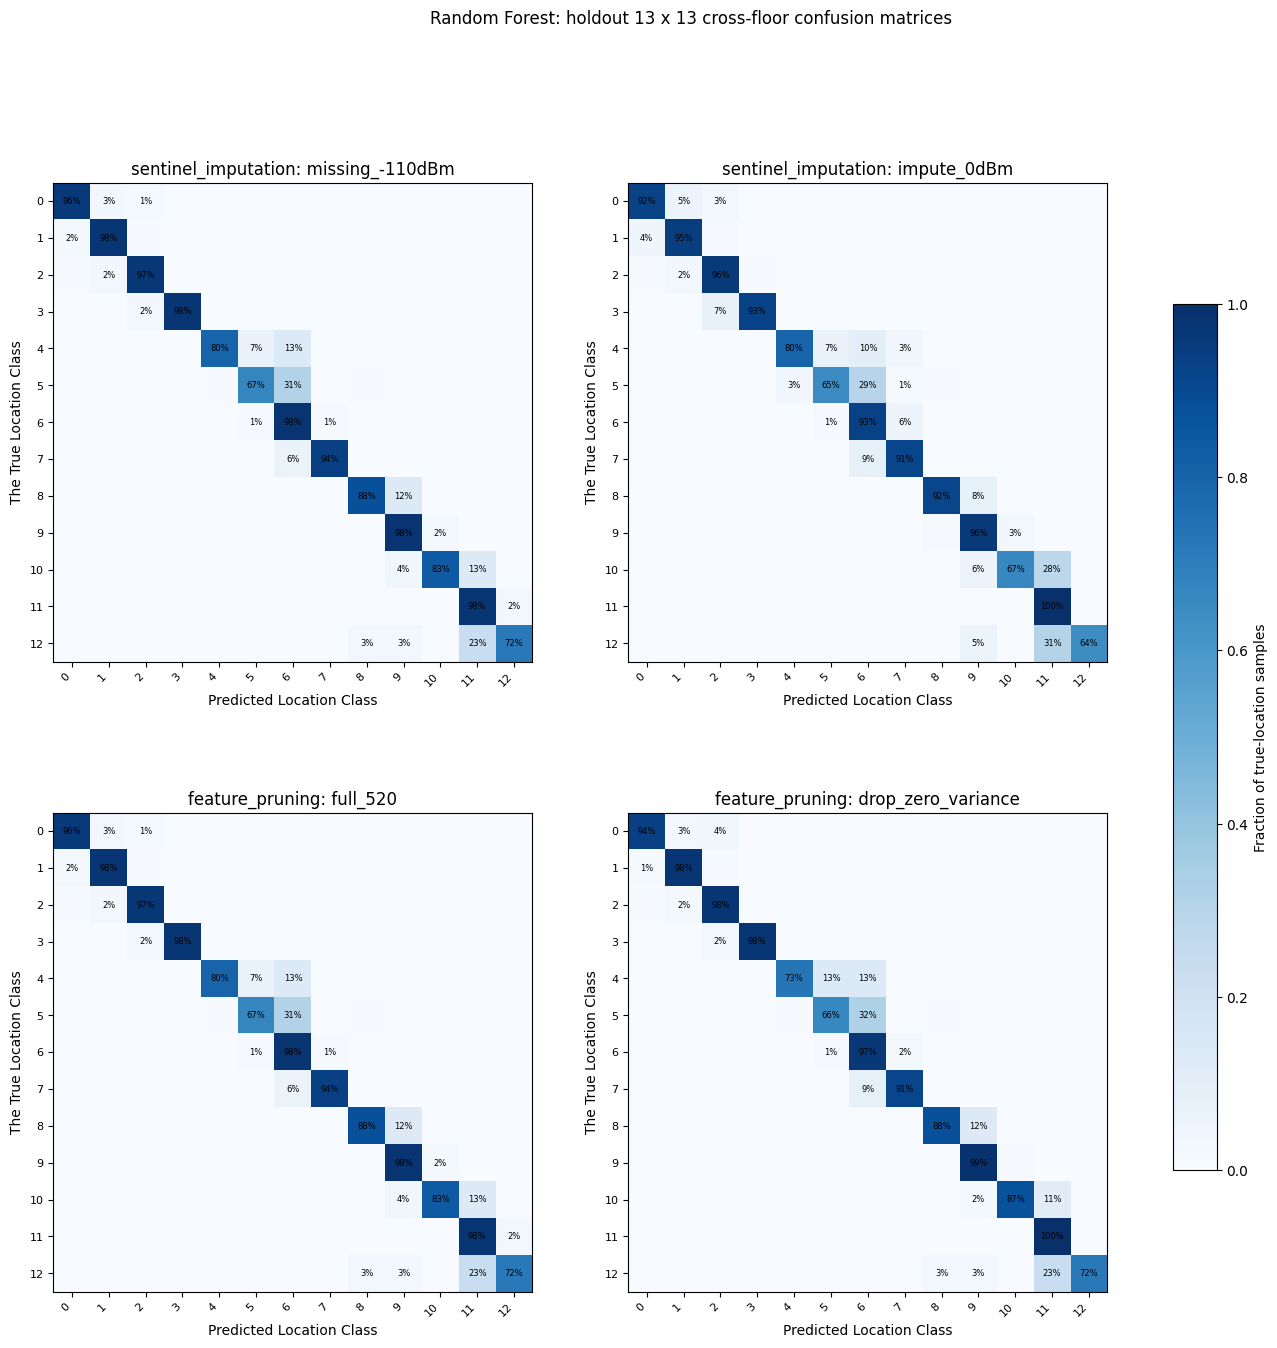

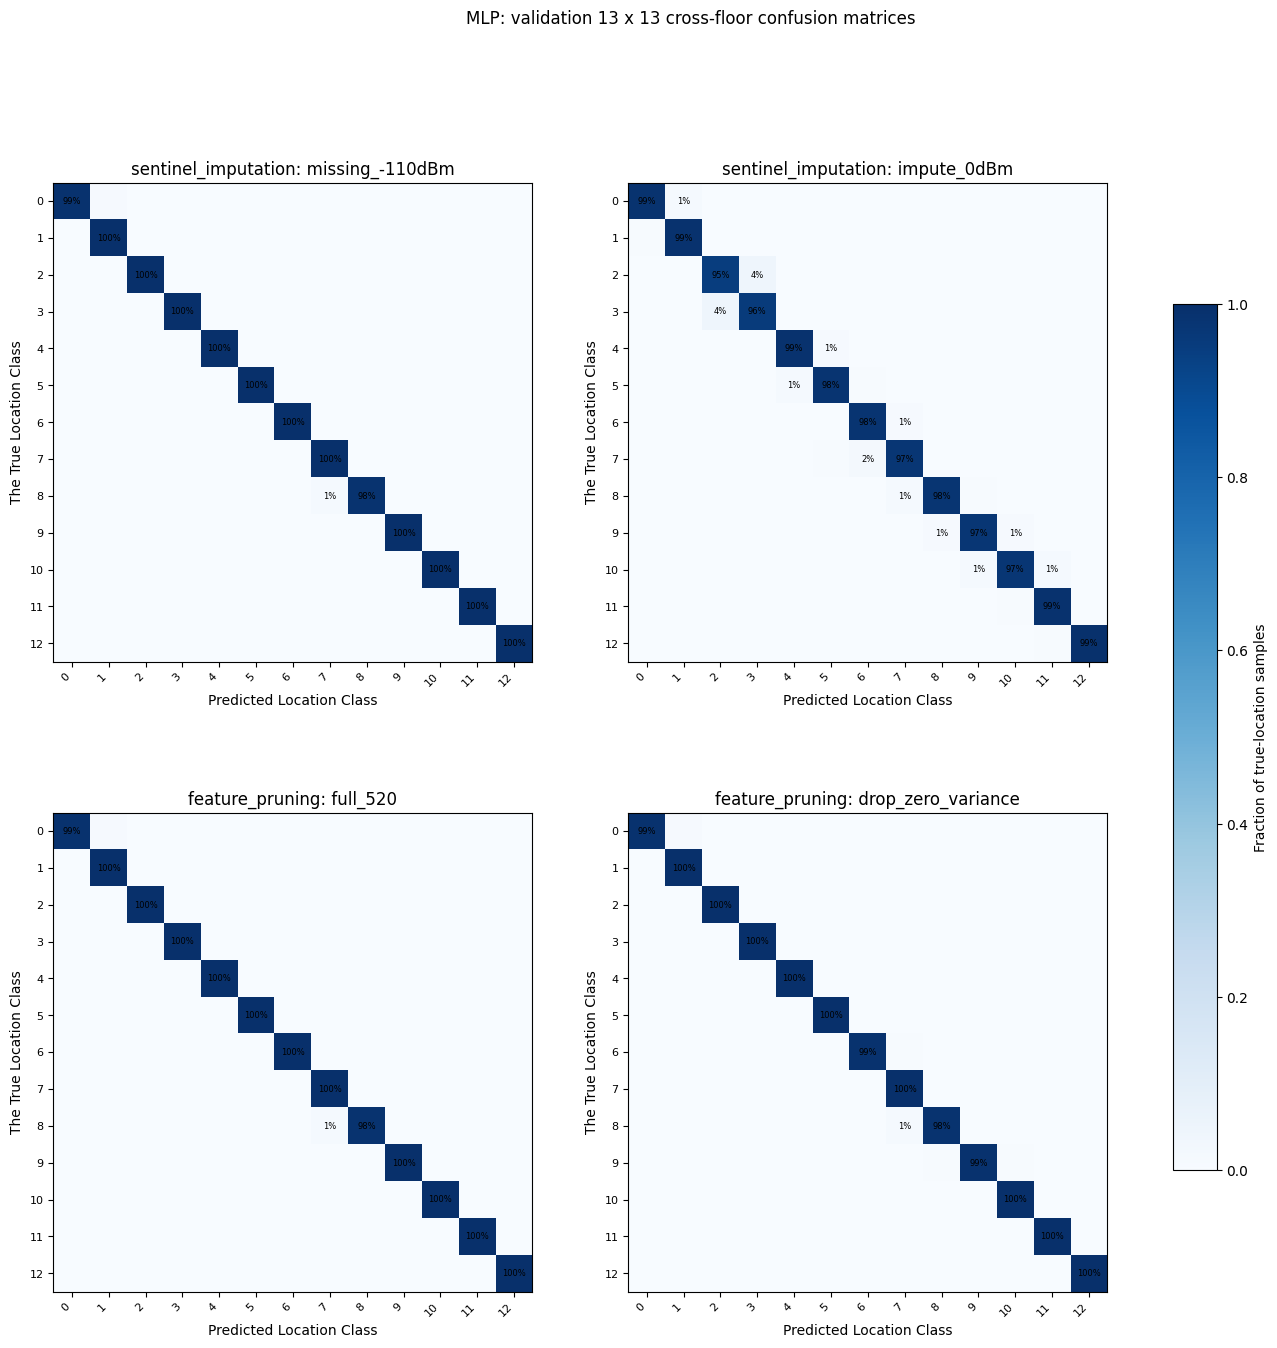

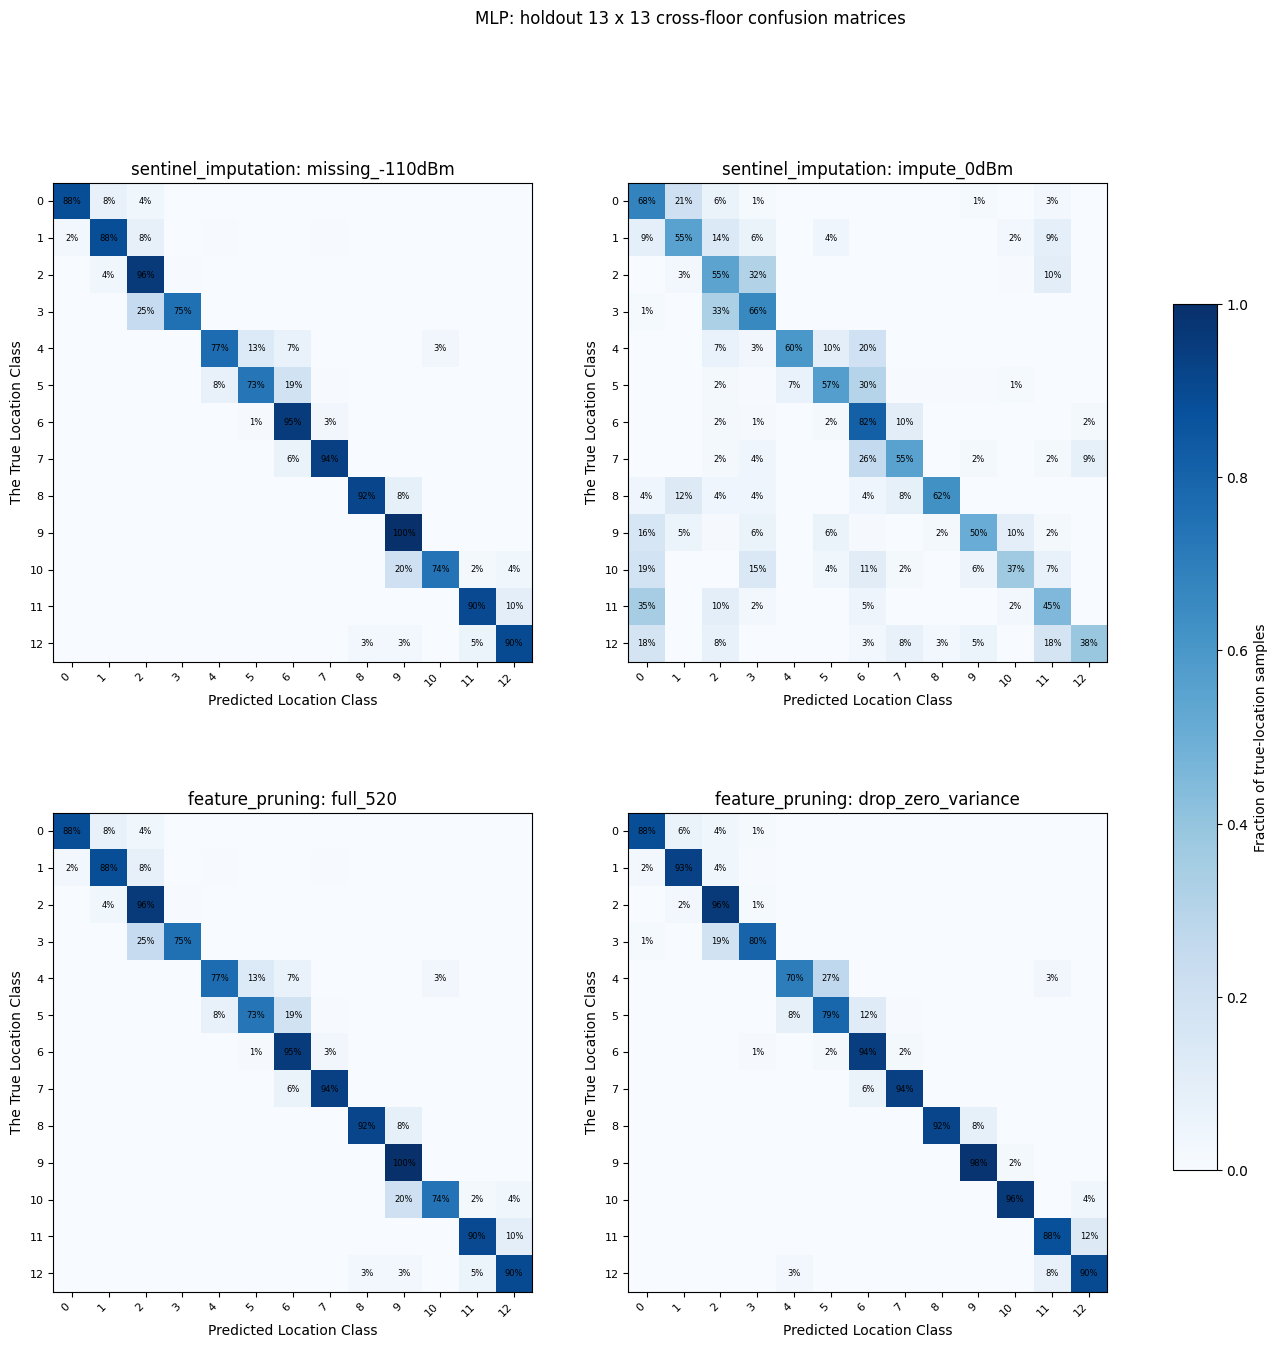

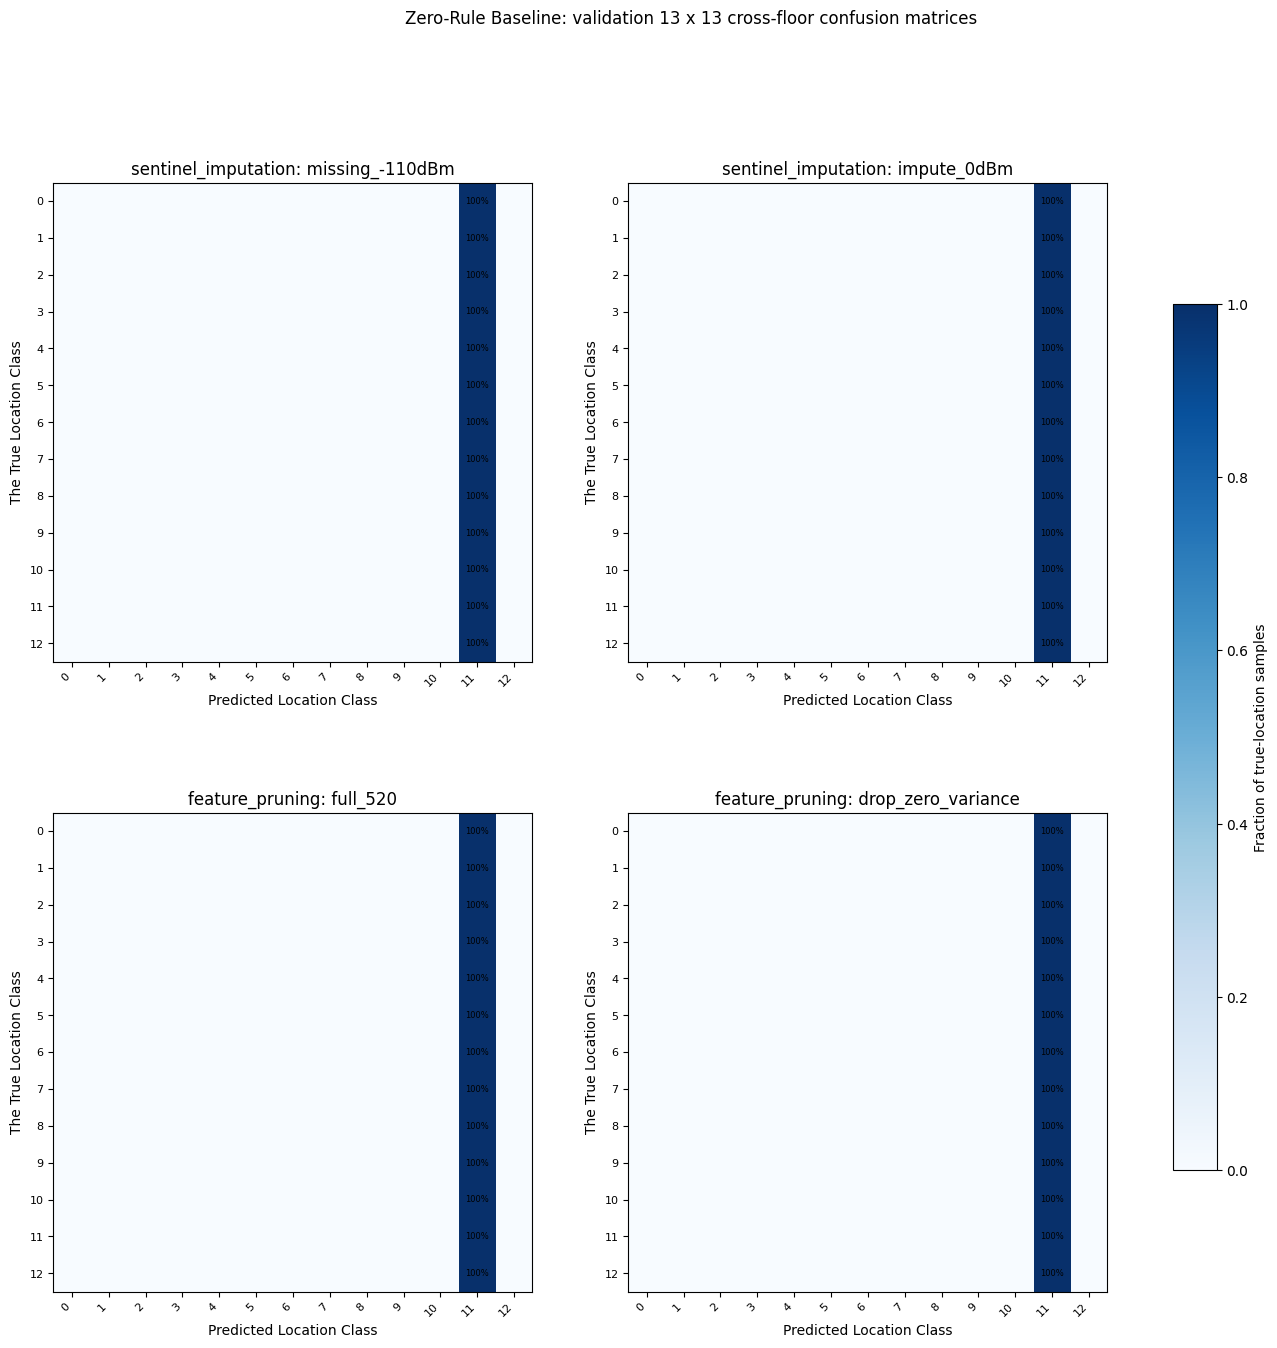

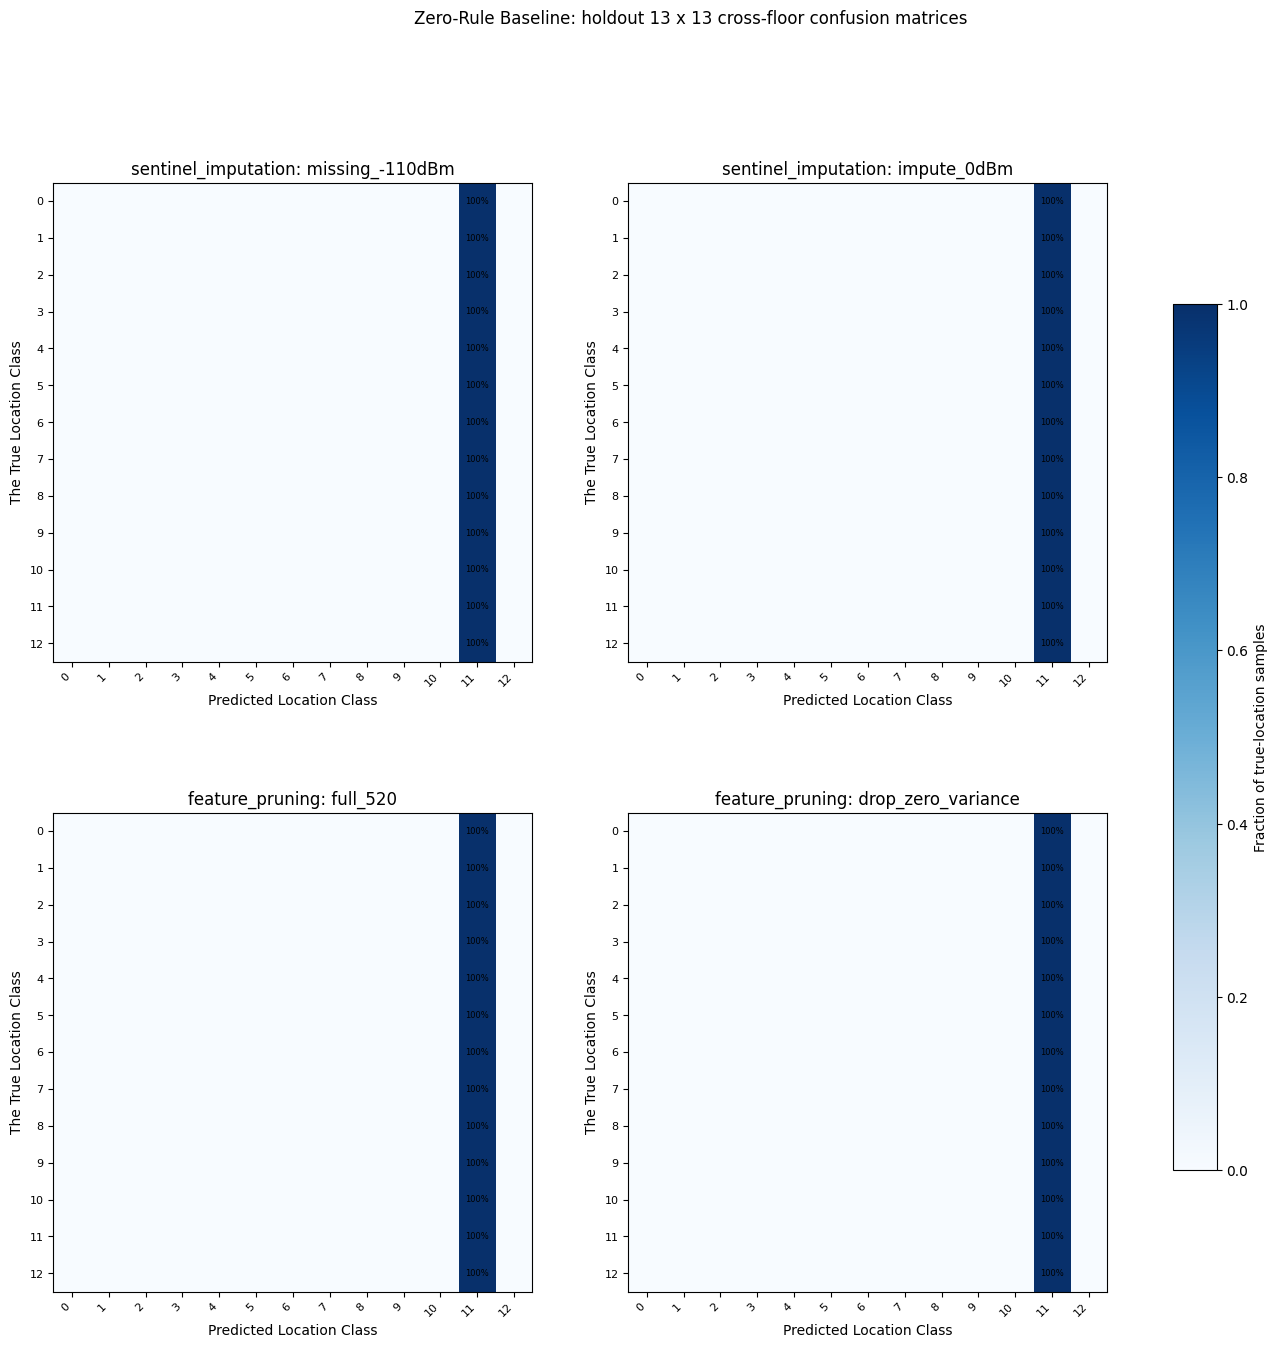

Saved 13 x 13 count and row-normalized matrices to: C:\Users\Madis\Downloads\ablation_outputs\cross_floor_matrices


In [13]:
def to_floor_ids(location_classes):
    unknown = set(np.unique(location_classes)) - set(CLASS_TO_FLOOR_ID)
    if unknown:
        raise ValueError(f"Cannot map predicted LOCATION_CLASS values to floors: {sorted(unknown)}")
    return np.fromiter(
        (CLASS_TO_FLOOR_ID[class_id] for class_id in location_classes),
        dtype=int,
        count=len(location_classes),
    )


CROSS_FLOOR_EXPERIMENTS = [
    (A_GROUP, "missing_-110dBm"),
    (A_GROUP, "impute_0dBm"),
    (B_GROUP, "full_520"),
    (B_GROUP, "drop_zero_variance"),
]
CROSS_FLOOR_DIR = OUT_DIR / "cross_floor_matrices"
CROSS_FLOOR_DIR.mkdir(parents=True, exist_ok=True)
matrices = {}

for group, experiment in CROSS_FLOOR_EXPERIMENTS:
    for model_name in MODELS:
        validation_pred, holdout_pred = preds[(group, experiment, model_name)]
        for split_name, true_labels, predicted_labels in [
            ("validation", y_te, validation_pred),
            ("holdout", y_ho, holdout_pred),
        ]:
            counts = confusion_matrix(
                to_floor_ids(true_labels),
                to_floor_ids(predicted_labels),
                labels=np.arange(len(LABELS)),
            )
            row_totals = counts.sum(axis=1, keepdims=True)
            row_normalized = np.divide(
                counts,
                row_totals,
                out=np.zeros_like(counts, dtype=float),
                where=row_totals != 0,
            )
            stem = f"{group}_{experiment}_{model_name.replace(' ', '_')}_{split_name}"
            pd.DataFrame(counts, index=FLOOR_LABELS, columns=FLOOR_LABELS).to_csv(
                CROSS_FLOOR_DIR / f"{stem}_counts.csv"
            )
            pd.DataFrame(row_normalized, index=FLOOR_LABELS, columns=FLOOR_LABELS).to_csv(
                CROSS_FLOOR_DIR / f"{stem}_row_normalized.csv"
            )
            matrices[(group, experiment, model_name, split_name)] = row_normalized

for model_name in MODELS:
    for split_name in ("validation", "holdout"):
        fig, axes = plt.subplots(2, 2, figsize=(17, 15), squeeze=False)
        image = None
        for ax, (group, experiment) in zip(axes.ravel(), CROSS_FLOOR_EXPERIMENTS):
            matrix = matrices[(group, experiment, model_name, split_name)]
            image = ax.imshow(matrix, cmap="Blues", vmin=0.0, vmax=1.0)
            ax.set_title(f"{group}: {experiment}")
            ax.set_xticks(np.arange(len(LABELS)))
            ax.set_yticks(np.arange(len(LABELS)))
            ax.set_xticklabels(LABELS, rotation=45, ha="right", fontsize=8)
            ax.set_yticklabels(LABELS, fontsize=8)
            ax.set_xlabel("Predicted Location Class")
            ax.set_ylabel("The True Location Class")
            for i, j in zip(*np.where(matrix >= 0.01)):
                ax.text(j, i, f"{matrix[i, j]:.0%}", ha="center", va="center", fontsize=6)
        fig.colorbar(image, ax=axes.ravel().tolist(), shrink=0.75, label="Fraction of true-location samples")
        fig.suptitle(f"{model_name}: {split_name} 13 x 13 cross-floor confusion matrices")
        fig.savefig(
            CROSS_FLOOR_DIR / f"cross_floor_{model_name.replace(' ', '_')}_{split_name}.png",
            dpi=160,
            bbox_inches="tight",
        )
        plt.show()
        plt.close(fig)

print(f"Saved 13 x 13 count and row-normalized matrices to: {CROSS_FLOOR_DIR.resolve()}")


# Results Summary

In [14]:
for group, experiment in CROSS_FLOOR_EXPERIMENTS:
    subset = results[(results["group"] == group) & (results["experiment"] == experiment)]
    print(f"\n{group}: {experiment}")
    print(subset[["model", "n_features", "val_macro_f1", "holdout_macro_f1"]].to_string(index=False))

print(f"\nAblation metrics: {(OUT_DIR / 'ablation_results.csv').resolve()}")
print(f"Cross-floor matrices and plots: {CROSS_FLOOR_DIR.resolve()}")



sentinel_imputation: missing_-110dBm
             model  n_features  val_macro_f1  holdout_macro_f1
               MLP         520      0.996536          0.870549
     Random Forest         520      0.994811          0.896860
Zero-Rule Baseline         520      0.018942          0.005347
              k-NN         520      0.994673          0.820915

sentinel_imputation: impute_0dBm
             model  n_features  val_macro_f1  holdout_macro_f1
               MLP         520      0.977744          0.559895
     Random Forest         520      0.992912          0.857727
Zero-Rule Baseline         520      0.018942          0.005347
              k-NN         520      0.986440          0.725498

feature_pruning: full_520
             model  n_features  val_macro_f1  holdout_macro_f1
               MLP         520      0.996536          0.870549
     Random Forest         520      0.994811          0.896860
Zero-Rule Baseline         520      0.018942          0.005347
              k-NN 